# OSSL and Fukushima spectra

> Compare the Fukushima MIR spectra with OSSL in a PCA fitted on OSSL, and look for instrument effects such as water vapour

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspectfm.preprocessing import SNV, SavitzkyGolay
from ossl_fuku_transfer.data import load_fuku, sample_batches, shared_wns

Every code cell reads OSSL or the Fukushima data, so every cell is marked `#| fukudata`. The outputs come from a local run.

## Data

OSSL MIR spectra, on the grid that OSSL and Fukushima share: 2 cm⁻¹ from 650 to 3998 cm⁻¹:

In [ ]:
#| fukudata
ossl = load_ossl()
om = ossl.mir(wmin=shared_wns[0], wmax=shared_wns[-1])
test_eq(om.wavenumbers, shared_wns)
om.spectra.shape

(85684, 1675)

OSSL gives the USDA soil taxonomy name of a pedon in `pedon.taxa_usda_txt`. Andisol great groups end in "-and", such as Hapludand. Older names end in "-andept". The Andisols are the closest OSSL counterpart of the Fukushima Andosols:

In [ ]:
#| fukudata
taxa = ossl['pedon.taxa_usda_txt'].reindex(om.sample_ids).astype('string')
is_andisol = taxa.str.contains(r'[a-z]ands?\b|andepts?\b', na=False).to_numpy()
int(taxa.notna().sum()), int(is_andisol.sum()), taxa[is_andisol].sample(4, random_state=0).tolist()

(40075,
 1735,
 ['Ashy over loamy, amorphic over mixed, mesic Aquic Vitrixerand',
  'Medial, amorphic, mesic Vitric Hapludand',
  'Ashy over loamy, amorphic over  isotic, frigid Typic Udivitrand',
  'Typic Haplustand'])

The Fukushima spectra, with each sample's soil type and measurement batch. The batches are the folders of `.spa` files:

In [ ]:
#| fukudata
fuku = load_fuku()
soil = fuku.source.loc[fuku.sample_ids, 'Soil_type_describe'].to_numpy()
batch = sample_batches(fuku.sample_ids)
pd.Series(soil).value_counts().to_dict(), pd.Series(batch).value_counts().to_dict()

({'Lowland soil': 907,
  'Andosols': 213,
  'Forest soil': 138,
  'Peat soil': 66,
  'Red yellow soil': 46,
  'Glay soil': 16},
 {'batch 2': 854, 'batch 1': 535})

## Mean spectra

Atmospheric gases in the beam path add narrow lines to MIR spectra. Water vapour absorbs between about 1300 and 2000 cm⁻¹ and between about 3500 and 3950 cm⁻¹. CO₂ absorbs between about 2280 and 2390 cm⁻¹, and below 720 cm⁻¹. The plots shade these regions:

In [ ]:
#| fukudata
gas_bands = {'H₂O': [(1300, 2000), (3500, 3950)], 'CO₂': [(650, 720), (2280, 2390)]}

def shade(ax):
    for (gas, bands), color in zip(gas_bands.items(), ['tab:blue', 'tab:gray']):
        for lo, hi in bands: ax.axvspan(lo, hi, color=color, alpha=0.1, lw=0)
    ax.invert_xaxis()
    ax.set_xlabel('Wavenumber (cm⁻¹)')

After SNV, the mean Fukushima Andosol spectrum differs from the mean OSSL Andisol spectrum:

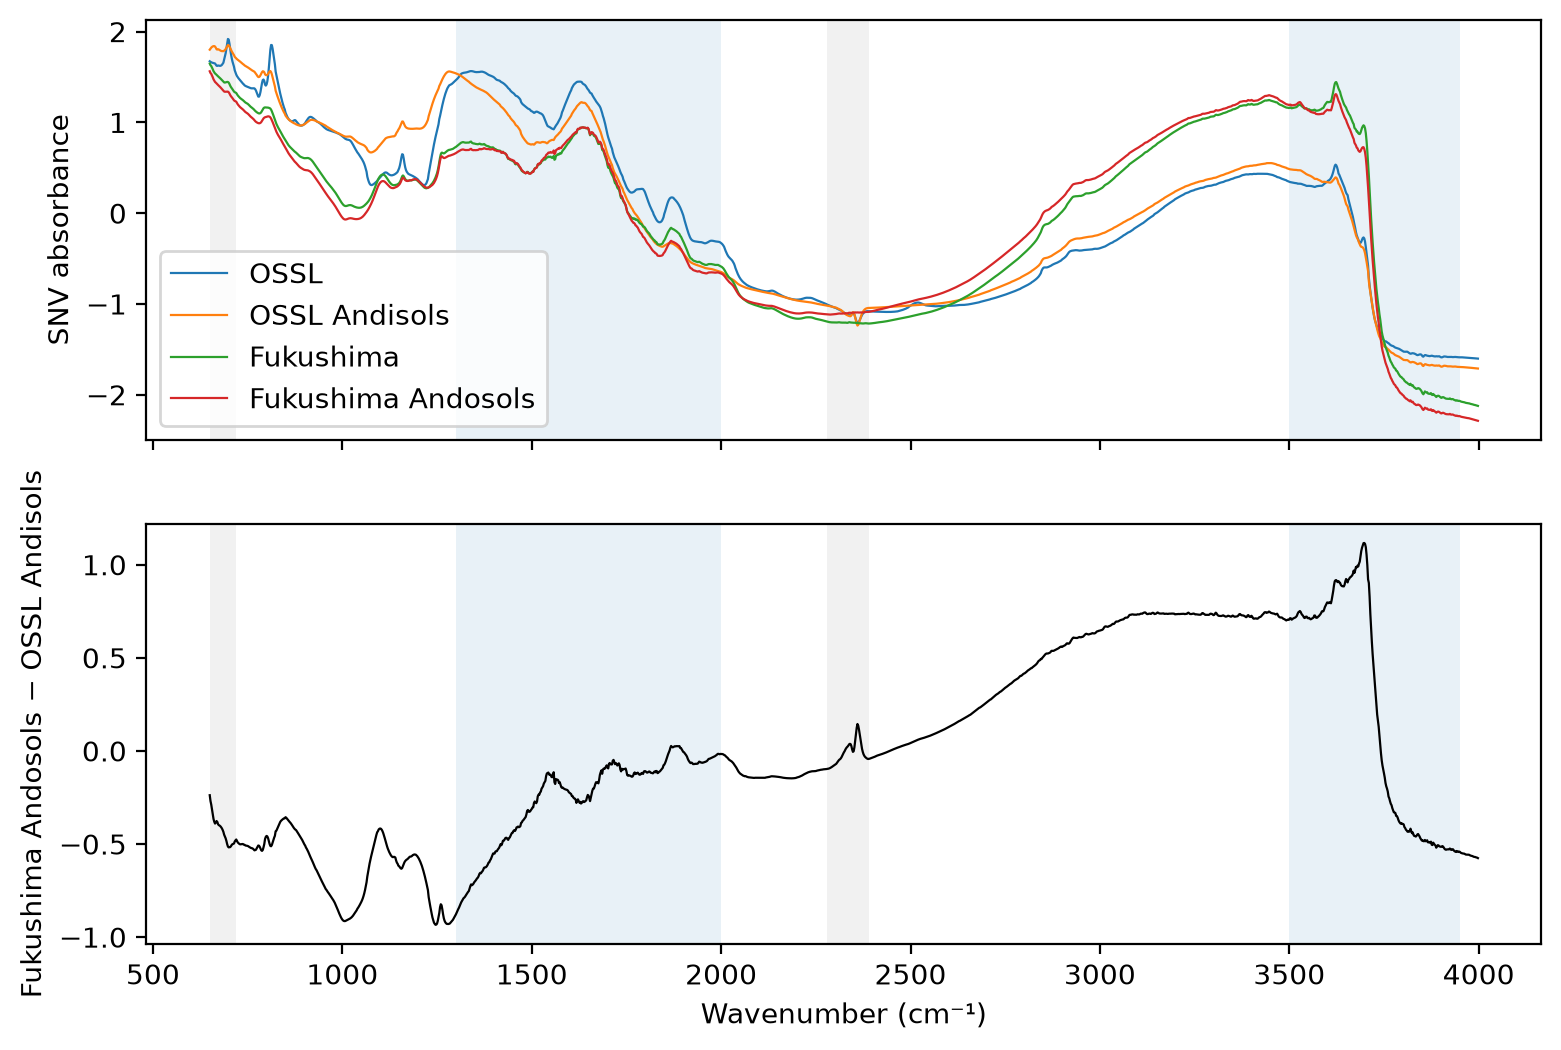

In [ ]:
#| fukudata
snv = SNV()
Xo, Xf = snv.fit_transform(om.spectra), snv.transform(fuku.spectra)
means = {'OSSL': Xo.mean(0), 'OSSL Andisols': Xo[is_andisol].mean(0),
         'Fukushima': Xf.mean(0), 'Fukushima Andosols': Xf[soil == 'Andosols'].mean(0)}
fig, axs = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for k, m in means.items(): axs[0].plot(shared_wns, m, lw=0.8, label=k)
axs[0].legend(); axs[0].set_ylabel('SNV absorbance')
axs[1].plot(shared_wns, means['Fukushima Andosols'] - means['OSSL Andisols'], lw=0.8, color='k')
axs[1].set_ylabel('Fukushima Andosols − OSSL Andisols')
for ax in axs: shade(ax)
axs[0].set_xlabel('');

Gas lines are narrower than soil absorption bands. Subtracting a smoothed copy of each spectrum keeps the narrow structure. Its mean size at each wavenumber compares the two instruments:

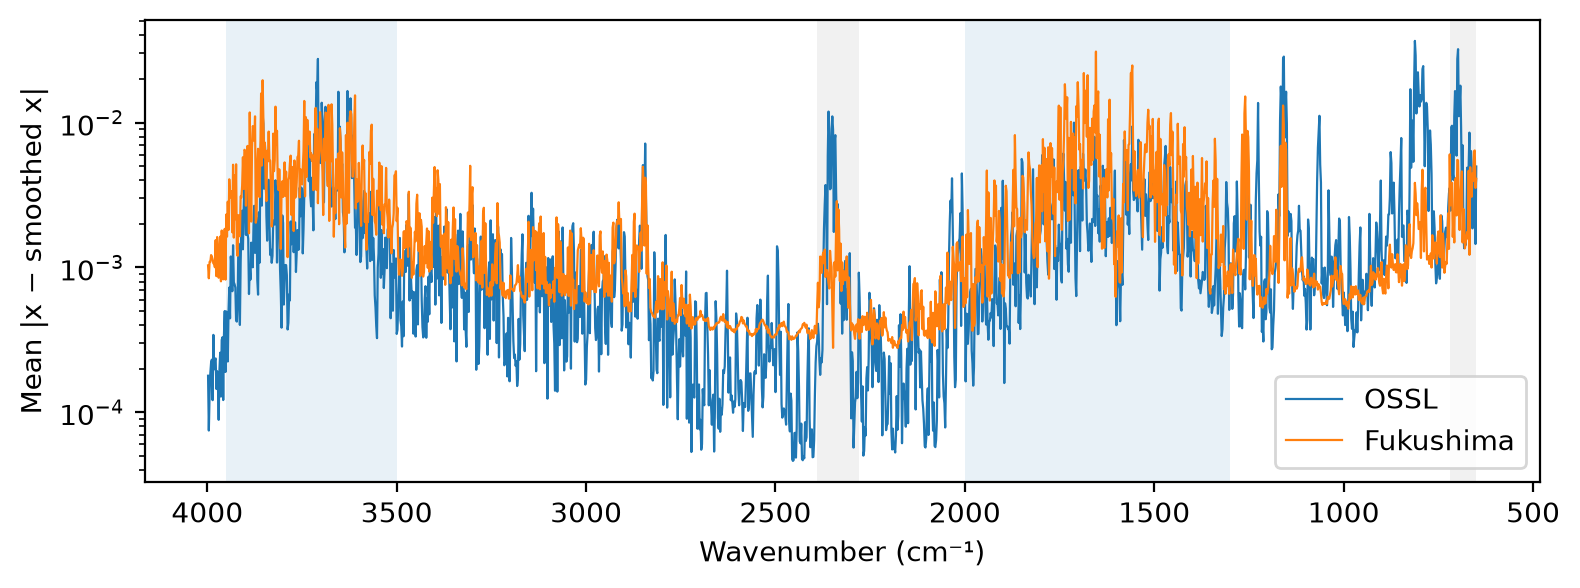

,OSSL,Fukushima,ratio
H₂O 1300–2000,0.00203,0.00436,2.14486
H₂O 3500–3950,0.00321,0.00499,1.55446
CO₂ 2280–2390,0.00209,0.00088,0.42332
quiet 2400–2800,0.00026,0.00042,1.62329


In [ ]:
#| fukudata
smooth = SavitzkyGolay(window_length=11, polyorder=2)
rough = {'OSSL': np.abs(Xo - smooth.transform(Xo)).mean(0), 'Fukushima': np.abs(Xf - smooth.transform(Xf)).mean(0)}
fig, ax = plt.subplots(figsize=(9, 3))
for k, r in rough.items(): ax.plot(shared_wns, r, lw=0.8, label=k)
ax.set_yscale('log'); ax.set_ylabel('Mean |x − smoothed x|'); ax.legend(); shade(ax)
in_band = lambda lo, hi: (shared_wns >= lo) & (shared_wns <= hi)
regions = {'H₂O 1300–2000': in_band(1300, 2000), 'H₂O 3500–3950': in_band(3500, 3950), 'CO₂ 2280–2390': in_band(2280, 2390), 'quiet 2400–2800': in_band(2400, 2800)}
pd.DataFrame({k: {n: r[m].mean() for n, m in regions.items()} for k, r in rough.items()}).assign(ratio=lambda d: d.Fukushima / d.OSSL).round(5)

## PCA

Each preprocessing is fitted on OSSL, then applied to the Fukushima spectra. The PCA, with 10 components, is fitted on OSSL only. `T2` is Hotelling's T², the distance within the PCA model. `Q` is the squared residual, the part of a spectrum the model does not explain:

In [ ]:
#| fukudata
pipes = {'SNV': make_pipeline(SNV()),
         'SNV + SG first derivative': make_pipeline(SNV(), SavitzkyGolay(window_length=11, polyorder=2, deriv=1))}

def fit_pca(pipe, n=10):
    Xo = pipe.fit_transform(om.spectra); Xf = pipe.transform(fuku.spectra)
    pca = PCA(n_components=n, svd_solver='randomized', random_state=0).fit(Xo)
    To, Tf = pca.transform(Xo), pca.transform(Xf)
    Eo, Ef = Xo - pca.inverse_transform(To), Xf - pca.inverse_transform(Tf)
    t2 = lambda T: (T**2 / pca.explained_variance_).sum(1)
    return dict(pca=pca, To=To, Tf=Tf, T2o=t2(To), T2f=t2(Tf), Qo=(Eo**2).sum(1), Qf=(Ef**2).sum(1), ro=(Eo**2).mean(0), rf=(Ef**2).mean(0))

res = {k: fit_pca(p) for k, p in pipes.items()}
{k: r['pca'].explained_variance_ratio_[:5].round(3).tolist() for k, r in res.items()}

{'SNV': [0.441, 0.215, 0.12, 0.077, 0.039],
 'SNV + SG first derivative': [0.408, 0.178, 0.113, 0.055, 0.03]}

Scores on the first two components. Grey points are a random 10,000 OSSL spectra:

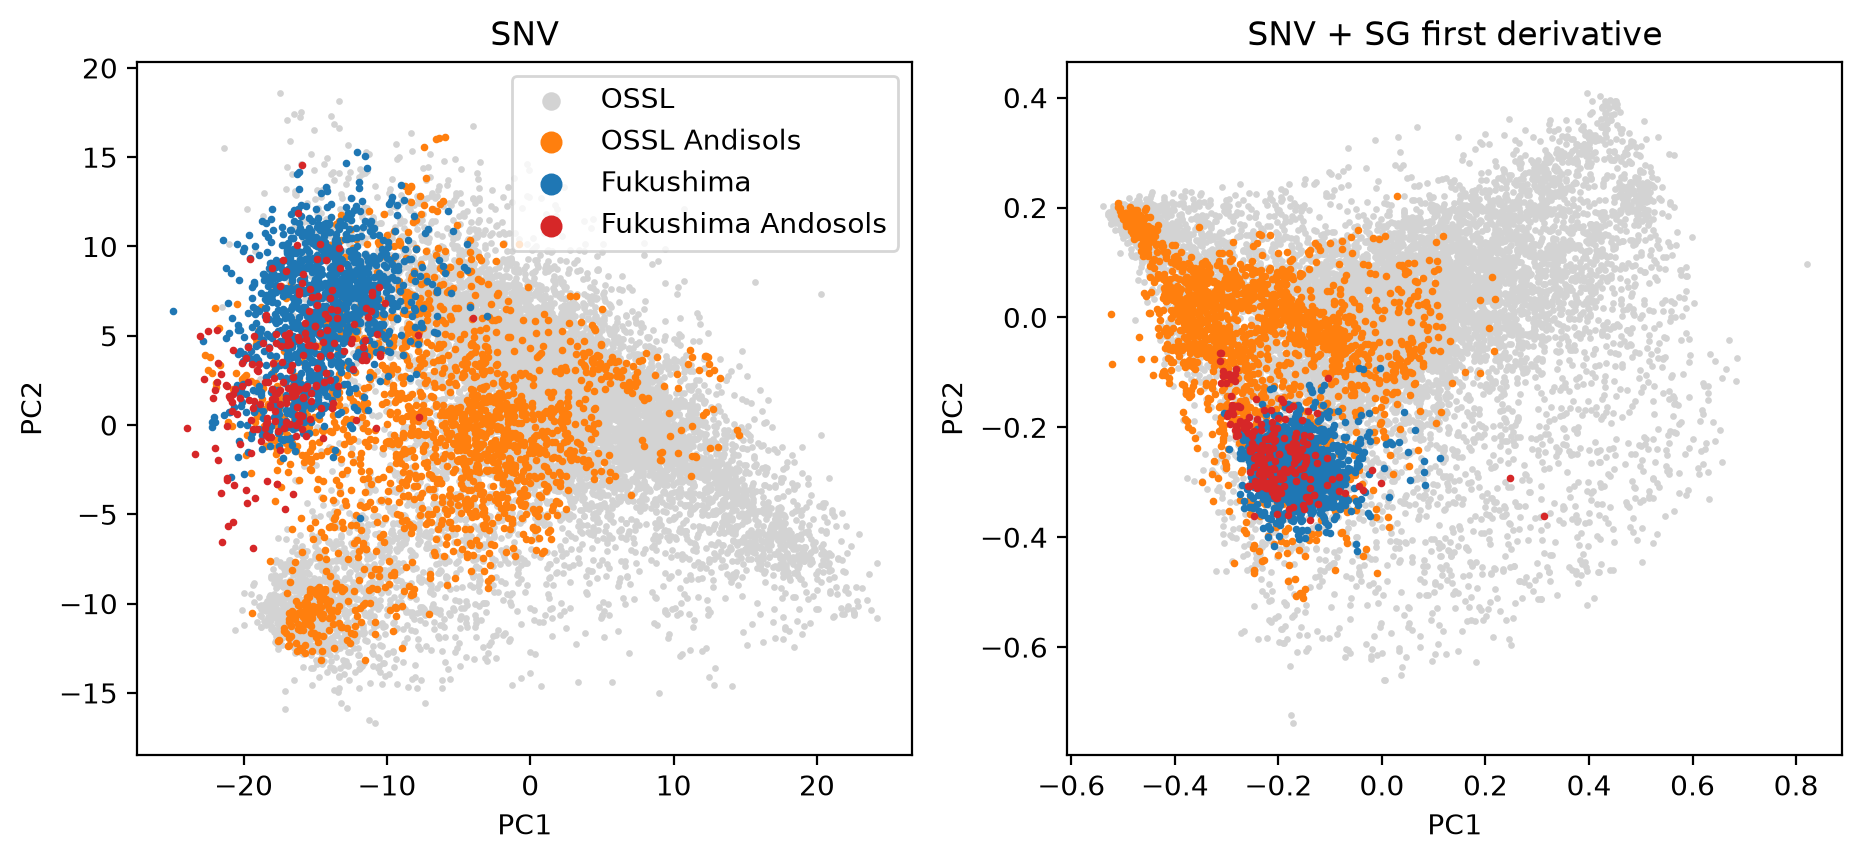

In [ ]:
#| fukudata
rng = np.random.default_rng(0)
sub = rng.choice(len(om.spectra), 10_000, replace=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (k, r) in zip(axs, res.items()):
    ax.scatter(*r['To'][sub, :2].T, s=2, c='lightgray', label='OSSL')
    ax.scatter(*r['To'][is_andisol, :2].T, s=3, c='tab:orange', label='OSSL Andisols')
    ax.scatter(*r['Tf'][soil != 'Andosols', :2].T, s=3, c='tab:blue', label='Fukushima')
    ax.scatter(*r['Tf'][soil == 'Andosols', :2].T, s=3, c='tab:red', label='Fukushima Andosols')
    ax.set_title(k); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
axs[0].legend(markerscale=4);

Group means of the scores, in standard deviations of the OSSL scores:

In [ ]:
#| fukudata
groups = {'OSSL Andisols': ('o', is_andisol), 'Fukushima Andosols': ('f', soil == 'Andosols'), 'Fukushima other soils': ('f', soil != 'Andosols')}
def std_means(r, n=3):
    sd = np.sqrt(r['pca'].explained_variance_[:n])
    return pd.DataFrame({g: r['T' + s][m, :n].mean(0) / sd for g, (s, m) in groups.items()}, index=[f'PC{j+1}' for j in range(n)]).T
pd.concat({k: std_means(r) for k, r in res.items()}, axis=1).round(2)

SNV             SNV + SG first derivative            
                        PC1   PC2   PC3                       PC1   PC2   PC3
OSSL Andisols         -0.75 -0.06  0.72                     -0.93 -0.23 -0.59
Fukushima Andosols    -1.99  0.48 -2.76                     -0.80 -1.46 -0.68
Fukushima other soils -1.72  1.08 -2.45                     -0.63 -1.65 -0.59

The share of each group beyond the 99th percentile of OSSL for `T2` and for `Q`:

In [ ]:
#| fukudata
def beyond(r, key):
    lim = np.quantile(r[key + 'o'], 0.99)
    return {'OSSL Andisols': (r[key + 'o'][is_andisol] > lim).mean(), 'Fukushima Andosols': (r[key + 'f'][soil == 'Andosols'] > lim).mean(),
            'Fukushima': (r[key + 'f'] > lim).mean()}
pd.DataFrame({(k, key): beyond(r, key) for k, r in res.items() for key in ('T2', 'Q')}).round(3)

SNV        SNV + SG first derivative       
                       T2      Q                        T2      Q
OSSL Andisols       0.002  0.013                       0.0  0.014
Fukushima Andosols  0.408  0.216                       0.0  0.005
Fukushima           0.224  0.073                       0.0  0.012

The mean squared residual at each wavenumber shows where the OSSL model fails to explain the Fukushima spectra. The table gives the ratio of the Fukushima mean to the OSSL mean in each region:

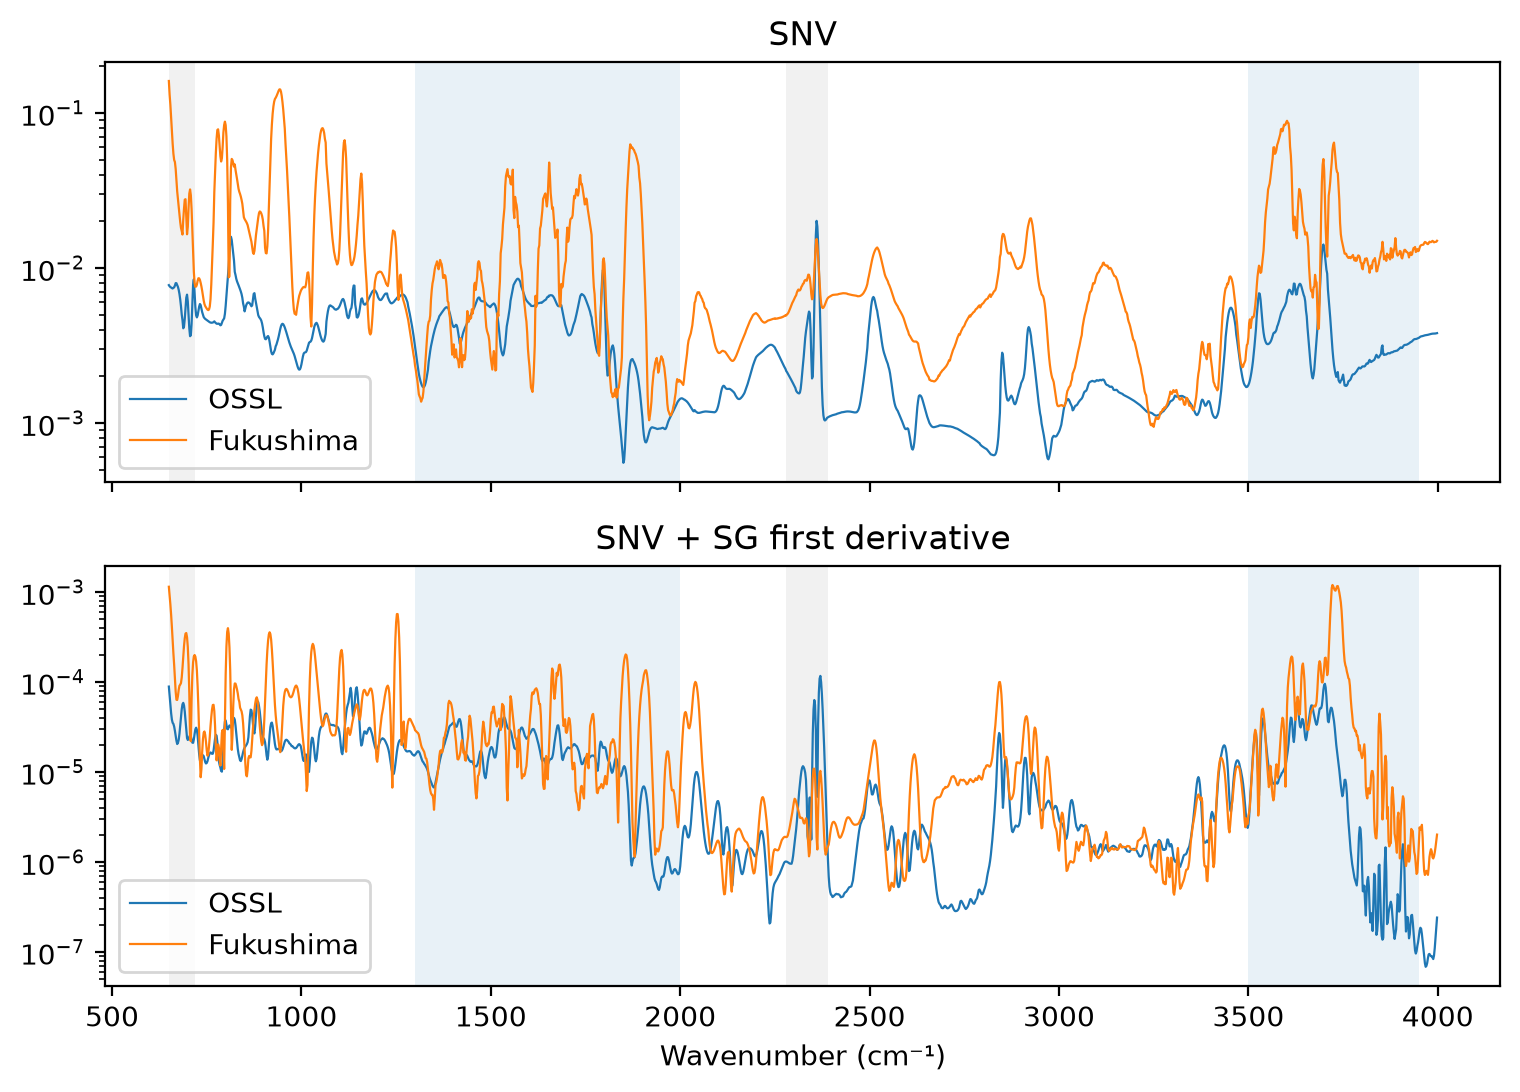

,SNV,SNV + SG first derivative
H₂O 1300–2000,3.08,2.12
H₂O 3500–3950,5.69,6.91
CO₂ 2280–2390,1.96,0.21
quiet 2400–2800,3.56,3.46


In [ ]:
#| fukudata
fig, axs = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, (k, r) in zip(axs, res.items()):
    ax.plot(shared_wns, r['ro'], lw=0.8, label='OSSL')
    ax.plot(shared_wns, r['rf'], lw=0.8, label='Fukushima')
    ax.set_yscale('log'); ax.set_title(k); ax.legend(); shade(ax)
axs[0].set_xlabel('')
pd.DataFrame({k: {n: r['rf'][m].mean() / r['ro'][m].mean() for n, m in regions.items()} for k, r in res.items()}).round(2)

## Within Fukushima

The two measurement batches, in the same scores. The table gives the batch means in standard deviations of the OSSL scores:

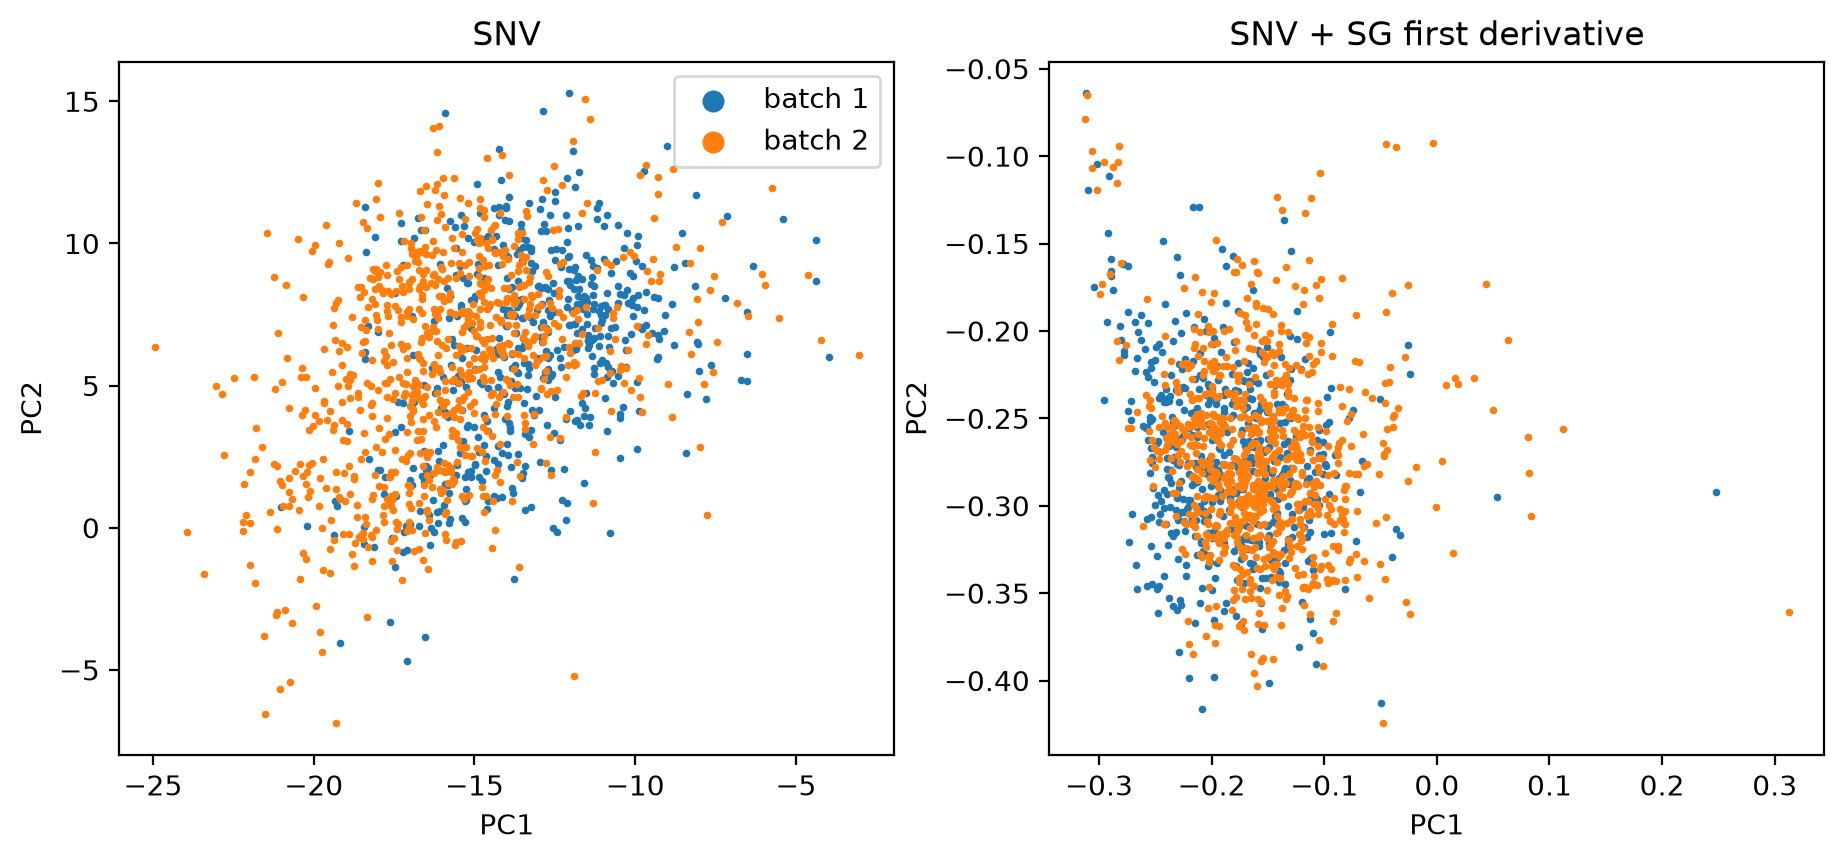

SNV             SNV + SG first derivative            
          PC1   PC2   PC3                       PC1   PC2   PC3
batch 1 -1.57  1.05 -2.02                     -0.73 -1.62 -0.65
batch 2 -1.88  0.95 -2.79                     -0.61 -1.62 -0.57

In [ ]:
#| fukudata
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (k, r) in zip(axs, res.items()):
    for b in np.unique(batch): ax.scatter(*r['Tf'][batch == b, :2].T, s=3, label=b)
    ax.set_title(k); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
axs[0].legend(markerscale=4)
pd.concat({k: pd.DataFrame(r['Tf'][:, :3] / np.sqrt(r['pca'].explained_variance_[:3]), columns=['PC1', 'PC2', 'PC3']).groupby(batch).mean() for k, r in res.items()}, axis=1).round(2)

## Findings

The figures in this section come from the tables above. They describe the current sample selection.

With SNV only, the Fukushima spectra sit away from OSSL. 22% of the Fukushima samples, and 41% of the Fukushima Andosols, are beyond the 99th percentile of OSSL's T². The Fukushima Andosols are no closer to the OSSL Andisols than the other Fukushima soils are. Both Fukushima groups sit between 1.7 and 2.0 standard deviations below the OSSL mean on PC1, and between 2.5 and 2.8 below it on PC3. The OSSL Andisols sit at -0.75 on PC1 and +0.72 on PC3. The Andosols and the other Fukushima soils share the offset. This points to the instrument or to sample handling common to all Fukushima samples, more than to the soils.

The Savitzky-Golay first derivative removes most of the offset. No Fukushima sample is beyond OSSL's 99th percentile of T², and 1.2% are beyond its 99th percentile of Q. An offset of about 1.5 standard deviations remains on PC2, against 0.2 for the OSSL Andisols. Most of the difference under SNV is therefore broad, such as baseline or slope.

The OSSL model leaves its largest Fukushima residuals between 3500 and 3950 cm⁻¹: 5.7 times the OSSL residual with SNV and 6.9 times with the derivative. In the quiet region from 2400 to 2800 cm⁻¹ the ratio is about 3.5. The narrow structure in 3500–3950 cm⁻¹ is not above that of the quiet region. The excess is a broad absorption, such as O–H from water held in the samples, more than water vapour lines.

Between 1300 and 2000 cm⁻¹, the Fukushima spectra have 2.1 times the narrow structure of OSSL, against 1.6 times in the quiet region. This excess is consistent with water vapour lines from the Nicolet's beam path. The Fukushima spectra were interpolated linearly from a step of about 1.93 cm⁻¹ to 2 cm⁻¹, which smooths narrow lines a little. The narrow-structure ratios may therefore understate the Nicolet's lines.

The CO₂ band is not a problem for Fukushima. Its spectra have less narrow structure there than OSSL (0.42 times), and the derivative model explains the band better for Fukushima than for OSSL.

The two Fukushima batches differ by about 0.8 standard deviations on PC3 with SNV. After the derivative their means differ by at most 0.12 standard deviations on each component. This notebook does not check whether the batches also differ in their soils.

Open questions for the Fukushima data team: how the samples were dried and stored before scanning, and whether the Nicolet was purged with dry air.